# 02 - Units and cities of SRV3490

**Intent.** SRV3490 rotation is suspected to be in rad/s while GBG500 (and the API schema) use deg/s. Before any shared use,
measure the ratio of per-ride standard deviations GBG500 / SRV3490 for each channel, with a seeded bootstrap 95% CI,
and compare it to 180/pi = 57.2958 for rotation and to 1 for acceleration. Then count rides and falls per city.
Nothing is converted here: the factor is only written to `params.yaml` after this check.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from ride_classifier.data.srv3490 import load_srv3490, ride_table
ROOT = Path.cwd()
if not (ROOT / "data").exists(): ROOT = ROOT.parent
CH = ["ax","ay","az","rx","ry","rz"]
srv = load_srv3490(ROOT/"data/raw/SRV3490.parquet", ["ride_id","crash_ride_id","city","time_index","topple"]+CH)
srv_std = srv.groupby("ride_id")[CH].std()
table = ride_table(srv[["ride_id","crash_ride_id","city","time_index","topple"]])
del srv
gbg = pd.read_parquet(ROOT/"data/raw/GBG500.parquet")
gbg_std = gbg.groupby("ride_id")[CH].std()
del gbg
print(len(srv_std), len(gbg_std))

3490 500


In [2]:
rng = np.random.default_rng(42)
B = 2000
rows = []
for c in CH:
    a, b = gbg_std[c].dropna().to_numpy(), srv_std[c].dropna().to_numpy()
    ratios = [np.median(rng.choice(a, a.size)) / np.median(rng.choice(b, b.size)) for _ in range(B)]
    lo, hi = np.percentile(ratios, [2.5, 97.5])
    rows.append((c, np.median(a), np.median(b), np.median(a)/np.median(b), lo, hi))
res = pd.DataFrame(rows, columns=["channel","median_std_GBG500","median_std_SRV3490","ratio","ci_low","ci_high"]).set_index("channel")
res["target"] = [1,1,1]+[180/np.pi]*3
res["target_in_ci"] = (res.ci_low <= res.target) & (res.target <= res.ci_high)
res.round(4)

,median_std_GBG500,median_std_SRV3490,ratio,ci_low,ci_high,target,target_in_ci
channel,,,,,,,
ax,0.7428,0.8930,0.8318,0.8078,0.8565,1.0000,False
ay,1.0152,1.0439,0.9725,0.9508,0.9980,1.0000,False
az,0.9104,1.1889,0.7658,0.7561,0.7766,1.0000,False
rx,5.3462,0.0881,60.6562,58.8980,62.0785,57.2958,False
ry,20.1414,0.3364,59.8694,58.2186,61.3180,57.2958,False
rz,7.8998,0.1316,60.0378,57.9642,61.4575,57.2958,False


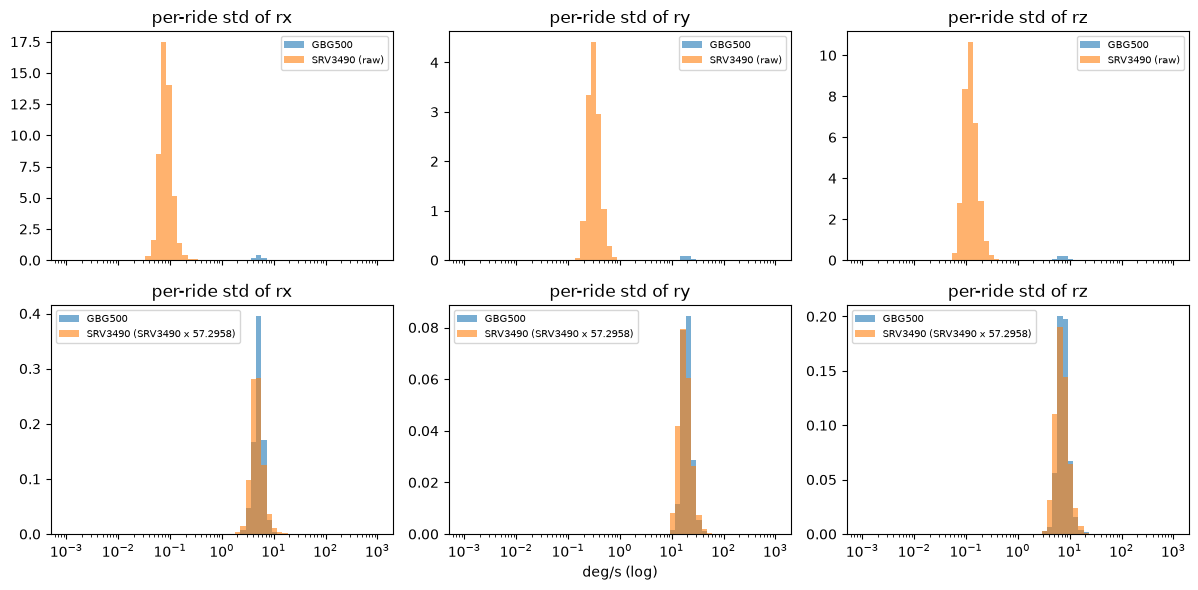

In [3]:
FACTOR = 180/np.pi
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex="col")
for j, c in enumerate(["rx","ry","rz"]):
    for i, (title, k) in enumerate([("raw", 1.0), ("SRV3490 x 57.2958", FACTOR)]):
        ax = axes[i, j]
        g, s = gbg_std[c].clip(lower=1e-6), srv_std[c].clip(lower=1e-6)*k
        bins = np.logspace(-3, 3, 60)
        ax.hist(g, bins=bins, alpha=.6, label="GBG500", density=True)
        ax.hist(s, bins=bins, alpha=.6, label="SRV3490 ("+title+")", density=True)
        ax.set_xscale("log"); ax.set_title(f"per-ride std of {c}"); ax.legend(fontsize=7)
axes[1,1].set_xlabel("deg/s (log)")
fig.tight_layout(); fig_units = fig

,rides,falls
city,,
0,40,8
1,190,38
2,35,7
3,245,49
4,600,120
5,80,16
6,1480,296
7,820,164


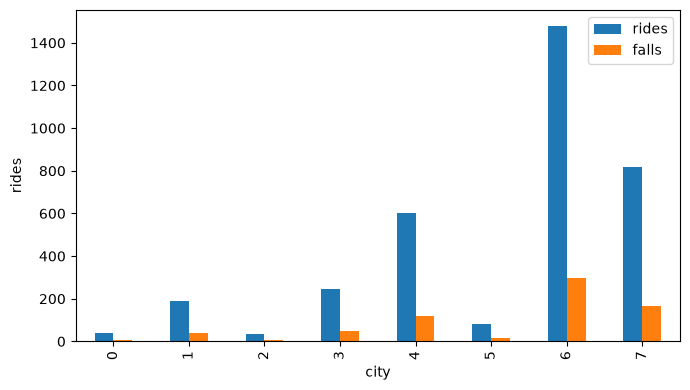

In [4]:
per_city = table.assign(fall=table.fall_time_index.notna()).groupby("city").agg(rides=("ride_id","size"), falls=("fall","sum"))
fig2, ax = plt.subplots(figsize=(7,4))
per_city.plot.bar(ax=ax); ax.set_xlabel("city"); ax.set_ylabel("rides"); fig2.tight_layout()
per_city

In [5]:
import importlib.util
if importlib.util.find_spec("ride_classifier.viz.theme"):
    from ride_classifier.viz.theme import apply_theme, save_fig
    apply_theme()
    save_fig(fig_units, "F04", "rotation_units"); save_fig(fig2, "F05", "rides_falls_per_city")
    print("figures saved")
else:
    print("theme module not found: no figure saved")

figures saved


## Reading of the results (written after running)

- Rotation: the GBG500 / SRV3490 median ratio of per-ride std is about 60 on all three channels (rx 60.7 [58.9, 62.1],
  ry 59.9 [58.2, 61.3], rz 60.0 [58.0, 61.5]). The factor is clearly ~60, not 1, so SRV3490 rotation is on a much smaller
  scale: consistent with rad/s versus deg/s.
- The 95% CIs do **not** contain 180/pi = 57.2958 (rz's lower bound 57.96 is just above it). The measured ratio is
  therefore about 5% higher than the exact unit conversion. Caveat: the two datasets contain different kinds of rides
  (SRV3490 mixes crash and baseline rides from other cities), so the ratio of medians also carries a population
  difference; it measures the order of magnitude and confirms the unit, not the exact constant.
- Acceleration: ratios 0.83 (ax), 0.97 (ay), 0.77 (az); CIs exclude 1 for ax and az, ay's upper bound is just below 1.
  Same order of magnitude (no unit issue, which would be a factor of 9.81 or 1000), with a population-level difference
  of up to ~25%.
- Cities: 8 cities, 3,490 rides, 698 rides with a fall (20% in each city, 4 baselines per crash ride), city 6 holds 42% of rides.

**Decision.** `params.yaml` uses the exact unit conversion 180/pi = 57.2958, not the measured ~60: a unit change is a
physical constant, and the ~5 % gap is of the same kind as the population differences seen on accelerations (3-23 %),
which share the same unit in both datasets.